# Madrid Rental Property Analysis
## SQL and Machine Learning on Idealista Rental Listings

**Dataset:** Idealista API rental listings for Madrid (`data/idealista_api_rent_madrid.csv`)

---

### Overview

This notebook analyzes rental listings for Madrid and the surrounding area, collected from the Idealista API. It covers:

- **Data cleaning**: duplicate removal, outlier filtering and feature engineering
- **SQL analysis**: the cleaned data is loaded into a SQLite database and queried for neighborhood, property type, amenity and size comparisons
- **Machine learning**: Linear Regression and Random Forest models that predict monthly rent
- **Statistical testing**: Welch's t-tests on rent with and without each amenity
- **Model validation**: hyperparameter search with GridSearchCV and 5-fold cross-validation

### Dataset

- **Source**: Idealista API (Spanish property portal)
- **Size**: 450 listings, 40 columns
- **Price range**: €340 to €750 per month
- **Terminology**: several fields and descriptions use Spanish property terms (a short reference is printed in section 1)

### Main Results

| Metric | Value |
|--------|-------|
| Listings after cleaning | 431 |
| Random Forest test MAE | €42 |
| Random Forest test R² | 0.295 |
| Linear Regression test MAE | €51 |
| Random Forest 5-fold CV MAE | €51 ± €6 |
| Test predictions within €100 | 92.0% |

## 1. Setup Environment and Load Libraries

Setting up the analysis environment with essential libraries for data processing, SQL operations, machine learning, and visualization.

In [34]:
import pandas as pd
import numpy as np
import sqlite3
import warnings
warnings.filterwarnings('ignore')

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style for better readability
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14

# Display settings for better output
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("All libraries loaded successfully!")

# Spanish terms dictionary for documentation
spanish_terms = {
    'precio': 'price (rental price in euros)',
    'superficie': 'surface area (size in square meters)', 
    'habitaciones': 'rooms (number of bedrooms)',
    'baños': 'bathrooms (number of bathrooms)',
    'barrio': 'neighborhood',
    'tipo_propiedad': 'property type',
    'terraza': 'terrace',
    'ascensor': 'elevator/lift',
    'parking': 'parking space'
}

print("\nSpanish Real Estate Terms Reference:")
for spanish, english in spanish_terms.items():
    print(f"   {spanish} = {english}")

All libraries loaded successfully!

Spanish Real Estate Terms Reference:
   precio = price (rental price in euros)
   superficie = surface area (size in square meters)
   habitaciones = rooms (number of bedrooms)
   baños = bathrooms (number of bathrooms)
   barrio = neighborhood
   tipo_propiedad = property type
   terraza = terrace
   ascensor = elevator/lift
   parking = parking space


## 2. Load and Explore Dataset

Loading the Idealista Madrid rental dataset and performing initial exploration to understand the data structure, column names (in Spanish), and basic statistics.

In [35]:
# Load the Madrid rental dataset
file_path = "data/idealista_api_rent_madrid.csv"

try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
except FileNotFoundError:
    print("Dataset file not found. Please check the file path.")
    
# Display basic information about the dataset
print("\n" + "="*50)
print("DATASET OVERVIEW")
print("="*50)

print(f"\nDataset Dimensions:")
print(f"   - Properties: {df.shape[0]:,}")
print(f"   - Features: {df.shape[1]}")

print(f"\nColumn Names (First 10):")
for i, col in enumerate(df.columns[:10]):
    print(f"   {i+1:2d}. {col}")
if len(df.columns) > 10:
    print(f"   ... and {len(df.columns)-10} more columns")

print(f"\nFirst 3 Properties Preview:")
print(df.head(3))

Dataset loaded successfully!
Dataset shape: 450 rows, 40 columns

DATASET OVERVIEW

Dataset Dimensions:
   - Properties: 450
   - Features: 40

Column Names (First 10):
    1. propertyCode
    2. thumbnail
    3. numPhotos
    4. price
    5. propertyType
    6. operation
    7. size
    8. exterior
    9. rooms
   10. bathrooms
   ... and 30 more columns

First 3 Properties Preview:
   propertyCode                                          thumbnail  numPhotos  \
0      98903350  https://img3.idealista.com/blur/WEB_LISTING/0/...         33   
1      91615378  https://img3.idealista.com/blur/WEB_LISTING/0/...         12   
2      88363329  https://img3.idealista.com/blur/WEB_LISTING/0/...         21   

   price propertyType operation   size  exterior  rooms  bathrooms  \
0  550.0       chalet      rent  371.0     False      6          3   
1  750.0         flat      rent   60.0      True      1          1   
2  750.0         flat      rent   70.0      True      2          1   

       

In [36]:
# Detailed Data Exploration
print("\n" + "="*50)
print("DETAILED DATA ANALYSIS")
print("="*50)

# Key columns analysis
key_columns = ['price', 'size', 'rooms', 'bathrooms', 'propertyType', 'neighborhood', 'district']
available_key_cols = [col for col in key_columns if col in df.columns]

print(f"\nPrice Statistics (Rental Prices in €):")
if 'price' in df.columns:
    price_stats = df['price'].describe()
    print(f"   - Mean: €{price_stats['mean']:.0f}/month")
    print(f"   - Median: €{price_stats['50%']:.0f}/month") 
    print(f"   - Range: €{price_stats['min']:.0f} - €{price_stats['max']:.0f}")
    print(f"   - Standard Deviation: €{price_stats['std']:.0f}")

print(f"\nProperty Size Analysis:")
if 'size' in df.columns:
    size_stats = df['size'].describe()
    print(f"   - Mean: {size_stats['mean']:.0f} m²")
    print(f"   - Median: {size_stats['50%']:.0f} m²")
    print(f"   - Range: {size_stats['min']:.0f} - {size_stats['max']:.0f} m²")

print(f"\nProperty Types Distribution:")
if 'propertyType' in df.columns:
    prop_types = df['propertyType'].value_counts()
    for prop_type, count in prop_types.head().items():
        percentage = (count / len(df)) * 100
        print(f"   - {prop_type}: {count} properties ({percentage:.1f}%)")

print(f"\nGeographic Distribution:")
if 'district' in df.columns:
    districts = df['district'].value_counts()
    print(f"   - Total Districts: {len(districts)}")
    print(f"   - Top 3 Districts:")
    for district, count in districts.head(3).items():
        percentage = (count / len(df)) * 100
        print(f"     - {district}: {count} properties ({percentage:.1f}%)")

# Missing values analysis
print(f"\nMissing Values Analysis:")
missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing %': missing_percent
}).sort_values('Missing %', ascending=False)

# Show only columns with missing values
missing_cols = missing_df[missing_df['Missing Count'] > 0].head(10)
if len(missing_cols) > 0:
    print("   Top columns with missing data:")
    for col, row in missing_cols.iterrows():
        print(f"   - {col}: {row['Missing Count']} ({row['Missing %']:.1f}%)")
else:
    print("   No missing values found!")


DETAILED DATA ANALYSIS

Price Statistics (Rental Prices in €):
   - Mean: €672/month
   - Median: €700/month
   - Range: €340 - €750
   - Standard Deviation: €85

Property Size Analysis:
   - Mean: 68 m²
   - Median: 62 m²
   - Range: 20 - 371 m²

Property Types Distribution:
   - flat: 356 properties (79.1%)
   - studio: 48 properties (10.7%)
   - duplex: 19 properties (4.2%)
   - penthouse: 16 properties (3.6%)
   - chalet: 9 properties (2.0%)

Geographic Distribution:
   - Total Districts: 98
   - Top 3 Districts:
     - Centro: 50 properties (11.1%)
     - Villaverde: 23 properties (5.1%)
     - Puente de Vallecas: 18 properties (4.0%)

Missing Values Analysis:
   Top columns with missing data:
   - newDevelopmentFinished: 433.0 (96.2%)
   - labels: 419.0 (93.1%)
   - parkingSpace: 303.0 (67.3%)
   - neighborhood: 269.0 (59.8%)
   - district: 100.0 (22.2%)
   - externalReference: 92.0 (20.4%)
   - floor: 67.0 (14.9%)
   - hasLift: 13.0 (2.9%)
   - description: 1.0 (0.2%)
   - thum

## 3. Data Cleaning and Preprocessing

Cleaning the data before analysis: handling missing values, correcting data types, removing duplicates and filtering outliers, followed by a few derived features.

In [37]:
# Data Cleaning and Preprocessing
print("STARTING DATA CLEANING PROCESS")
print("="*50)

# Store original dataset size
original_size = len(df)
print(f"Original dataset: {original_size:,} properties")

# Step 1: Handle critical missing values
print(f"\n1. Handling Missing Values in Critical Columns")
critical_columns = ['price', 'size']

# Check which critical columns exist and have data
available_critical = [col for col in critical_columns if col in df.columns]
print(f"   - Critical columns found: {available_critical}")

# Remove rows with missing values in critical columns
if available_critical:
    before_missing = len(df)
    df = df.dropna(subset=available_critical)
    after_missing = len(df)
    removed_missing = before_missing - after_missing
    print(f"   - Removed {removed_missing} properties with missing critical data")
    print(f"   - Remaining: {after_missing:,} properties")

# Step 2: Data type corrections
print(f"\n2. Data Type Corrections")
numeric_columns = ['price', 'size', 'rooms', 'bathrooms']

for col in numeric_columns:
    if col in df.columns:
        # Convert to numeric, handling any text values
        original_type = df[col].dtype
        df[col] = pd.to_numeric(df[col], errors='coerce')
        print(f"   - {col}: {original_type} -> {df[col].dtype}")

# Step 3: Remove duplicates
print(f"\n3. Removing Duplicate Properties")
before_duplicates = len(df)
df = df.drop_duplicates()
after_duplicates = len(df)
removed_duplicates = before_duplicates - after_duplicates
print(f"   - Removed {removed_duplicates} duplicate properties")
print(f"   - Remaining: {after_duplicates:,} properties")

# Step 4: Outlier detection and removal
print(f"\n4. Outlier Detection and Filtering")

# Price outliers (using improved range for Madrid market)
if 'price' in df.columns:
    # More realistic Madrid rental market range
    price_lower = df['price'].quantile(0.005)  # More lenient lower bound
    price_upper = df['price'].quantile(0.995)  # More lenient upper bound
    
    # Apply business logic for Madrid market
    min_reasonable_price = 300  # Minimum reasonable monthly rent in Madrid
    max_reasonable_price = 4000  # Maximum reasonable monthly rent for dataset
    
    Q1_price = max(price_lower, min_reasonable_price)
    Q3_price = min(price_upper, max_reasonable_price)
    
    before_outliers = len(df)
    df = df[(df['price'] >= Q1_price) & (df['price'] <= Q3_price)]
    after_outliers = len(df)
    removed_outliers = before_outliers - after_outliers
    
    print(f"   - Improved price range filter: €{Q1_price:.0f} - €{Q3_price:.0f}")
    print(f"   - Removed {removed_outliers} price outliers (more lenient approach)")
    print(f"   - Business logic: Market-realistic bounds for Madrid")

# Size outliers (remove unrealistic property sizes)
if 'size' in df.columns:
    Q1_size = df['size'].quantile(0.01)
    Q3_size = df['size'].quantile(0.99)
    
    before_size = len(df)
    df = df[(df['size'] >= Q1_size) & (df['size'] <= Q3_size)]
    after_size = len(df)
    removed_size = before_size - after_size
    
    print(f"   - Size range filter: {Q1_size:.0f}m² - {Q3_size:.0f}m²")
    print(f"   - Removed {removed_size} size outliers")

# Step 5: Feature Engineering - Create derived columns
print(f"\n5. Feature Engineering")

# Price per square meter (key metric for real estate)
if 'price' in df.columns and 'size' in df.columns:
    df['price_per_sqm'] = df['price'] / df['size']
    print(f"   - Created 'price_per_sqm' column")

# Property category simplification with improved handling
if 'propertyType' in df.columns:
    # Standardize property types with 'Other' category for unknowns
    property_mapping = {
        'flat': 'Apartment',
        'studio': 'Studio', 
        'penthouse': 'Penthouse',
        'duplex': 'Duplex',
        'chalet': 'House',
        'house': 'House'
    }
    
    df['property_category'] = df['propertyType'].map(property_mapping)
    # Use 'Other' instead of 'Unknown' for better model interpretation
    df['property_category'] = df['property_category'].fillna('Other')
    print(f"   - Created standardized 'property_category' column")
    
    # Show category distribution
    category_counts = df['property_category'].value_counts()
    print(f"   - Category distribution: {dict(category_counts)}")

# Binary features for amenities
amenity_columns = ['hasLift', 'exterior', 'parkingSpace']
for col in amenity_columns:
    if col in df.columns:
        # Convert boolean/text to binary
        df[f'{col}_binary'] = df[col].astype(str).str.lower().isin(['true', '1', 'yes', 'sí']).astype(int)
        print(f"   - Created binary feature: {col}_binary")

# Final summary
final_size = len(df)
total_removed = original_size - final_size
removal_percentage = (total_removed / original_size) * 100

print(f"\nCLEANING SUMMARY")
print(f"   - Original: {original_size:,} properties")
print(f"   - Cleaned: {final_size:,} properties")
print(f"   - Removed: {total_removed:,} properties ({removal_percentage:.1f}%)")

# Display cleaned dataset info
print(f"\nCleaned Dataset Overview:")
print(f"   - Shape: {df.shape}")
print(f"   - Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

STARTING DATA CLEANING PROCESS
Original dataset: 450 properties

1. Handling Missing Values in Critical Columns
   - Critical columns found: ['price', 'size']
   - Removed 0 properties with missing critical data
   - Remaining: 450 properties

2. Data Type Corrections
   - price: float64 -> float64
   - size: float64 -> float64
   - rooms: int64 -> int64
   - bathrooms: int64 -> int64

3. Removing Duplicate Properties
   - Removed 8 duplicate properties
   - Remaining: 442 properties

4. Outlier Detection and Filtering
   - Improved price range filter: €384 - €750
   - Removed 3 price outliers (more lenient approach)
   - Business logic: Market-realistic bounds for Madrid
   - Size range filter: 25m² - 212m²
   - Removed 8 size outliers

5. Feature Engineering
   - Created 'price_per_sqm' column
   - Created standardized 'property_category' column
   - Category distribution: {'Apartment': 345, 'Studio': 45, 'Duplex': 19, 'Penthouse': 15, 'House': 6, 'Other': 1}
   - Created binary feat

## 4. Create SQLite Database

Loading the cleaned dataset into a SQLite database table so it can be queried with SQL.

In [38]:
# Create SQLite Database for SQL Analysis
print("CREATING SQLITE DATABASE")
print("="*50)

# Database file path
db_path = "madrid_rentals.db"

try:
    # Create database connection
    conn = sqlite3.connect(db_path)
    print(f"Database connection established")
    print(f"Database location: {db_path}")
    
    # Load cleaned DataFrame into SQL table
    table_name = 'properties'
    df.to_sql(table_name, conn, if_exists='replace', index=False)
    
    print(f"Data loaded into '{table_name}' table")
    print(f"Records inserted: {len(df):,}")
    
    # Verify table creation
    cursor = conn.cursor()
    cursor.execute(f"SELECT COUNT(*) FROM {table_name}")
    record_count = cursor.fetchone()[0]
    print(f"Verification: {record_count:,} records in database")
    
    # Get table schema
    cursor.execute(f"PRAGMA table_info({table_name})")
    columns_info = cursor.fetchall()
    
    print(f"\nDatabase Schema ({table_name} table):")
    print(f"{'Column Name':<25} {'Data Type':<15} {'Nullable'}")
    print("-" * 55)
    
    for col_info in columns_info[:10]:  # Show first 10 columns
        col_name = col_info[1]
        col_type = col_info[2]
        nullable = "Yes" if col_info[3] == 0 else "No"
        print(f"{col_name:<25} {col_type:<15} {nullable}")
    
    if len(columns_info) > 10:
        print(f"... and {len(columns_info)-10} more columns")
    
    # Test basic query
    print(f"\nDatabase Test Query:")
    test_query = f"SELECT COUNT(*) as total_properties, AVG(price) as avg_price FROM {table_name} WHERE price IS NOT NULL"
    
    result = pd.read_sql_query(test_query, conn)
    print(f"   - Total Properties: {result['total_properties'].iloc[0]:,}")
    print(f"   - Average Price: €{result['avg_price'].iloc[0]:.0f}")
    
    print(f"\nDatabase ready for SQL analysis!")
    
except Exception as e:
    print(f"Error creating database: {e}")

# Keep connection open for next section
# conn will be used in the SQL analysis section

CREATING SQLITE DATABASE
Database connection established
Database location: madrid_rentals.db
Data loaded into 'properties' table
Records inserted: 431
Verification: 431 records in database

Database Schema (properties table):
Column Name               Data Type       Nullable
-------------------------------------------------------
propertyCode              INTEGER         Yes
thumbnail                 TEXT            Yes
numPhotos                 INTEGER         Yes
price                     REAL            Yes
propertyType              TEXT            Yes
operation                 TEXT            Yes
size                      REAL            Yes
exterior                  INTEGER         Yes
rooms                     INTEGER         Yes
bathrooms                 INTEGER         Yes
... and 35 more columns

Database Test Query:
   - Total Properties: 431
   - Average Price: €675

Database ready for SQL analysis!
Data loaded into 'properties' table
Records inserted: 431
Verification: 43

In [39]:
# Database Optimization - Index Creation for Performance
print(f"\nDATABASE OPTIMIZATION")
print("="*40)

try:
    cursor = conn.cursor()
    
    # Create indexes for commonly queried columns
    index_commands = [
        ("idx_price_neigh", "CREATE INDEX IF NOT EXISTS idx_price_neigh ON properties(neighborhood, price)"),
        ("idx_price_district", "CREATE INDEX IF NOT EXISTS idx_price_district ON properties(district, price)"),
        ("idx_property_type", "CREATE INDEX IF NOT EXISTS idx_property_type ON properties(property_category, price)"),
        ("idx_size_price", "CREATE INDEX IF NOT EXISTS idx_size_price ON properties(size, price)")
    ]
    
    print("Creating performance indexes:")
    for index_name, command in index_commands:
        cursor.execute(command)
        print(f"   {index_name}: Query optimization for price analysis")
    
    conn.commit()
    
    print(f"\nExpected benefits of the indexes:")
    print(f"   - Faster neighborhood price lookups")
    print(f"   - Optimized property type filtering")
    print(f"   - Faster district level aggregations")
    print(f"   - Scalable for larger datasets")
    
    # Test query performance improvement hint
    print(f"\nQuery Performance Tip:")
    print(f"   - Queries filtering by neighborhood + price will now be faster")
    print(f"   - Example: SELECT * FROM properties WHERE neighborhood='Malasaña' AND price BETWEEN 800 AND 1200")
    
except Exception as e:
    print(f"   Note: Index creation not critical for demo - {e}")

print(f"\nDatabase optimization completed!")


DATABASE OPTIMIZATION
Creating performance indexes:
   idx_price_neigh: Query optimization for price analysis
   idx_price_district: Query optimization for price analysis
   idx_property_type: Query optimization for price analysis
   idx_size_price: Query optimization for price analysis

Expected benefits of the indexes:
   - Faster neighborhood price lookups
   - Optimized property type filtering
   - Faster district level aggregations
   - Scalable for larger datasets

Query Performance Tip:
   - Queries filtering by neighborhood + price will now be faster
   - Example: SELECT * FROM properties WHERE neighborhood='Malasaña' AND price BETWEEN 800 AND 1200

Database optimization completed!


## 5. SQL Analysis - Property Market Insights

SQL queries on the `properties` table: the neighborhoods with the highest price per m², a summary by property type, rent with and without amenities, and price per m² by size segment.

In [40]:
# SQL Analysis - Market Queries
print("SQL MARKET ANALYSIS")
print("="*60)

# Query 1: Average Rental Prices by Neighborhood (Top 10 most expensive)
print("\n1. TOP 10 MOST EXPENSIVE NEIGHBORHOODS")
print("-" * 50)

query1 = """
SELECT 
    neighborhood,
    COUNT(*) as property_count,
    ROUND(AVG(price), 0) as avg_monthly_rent,
    ROUND(AVG(price_per_sqm), 2) as avg_price_per_sqm,
    ROUND(MIN(price), 0) as min_rent,
    ROUND(MAX(price), 0) as max_rent
FROM properties 
WHERE neighborhood IS NOT NULL 
    AND price IS NOT NULL 
    AND price_per_sqm IS NOT NULL
GROUP BY neighborhood
HAVING property_count >= 3
ORDER BY avg_price_per_sqm DESC
LIMIT 10
"""

try:
    result1 = pd.read_sql_query(query1, conn)
    print("Neighborhoods with the highest average price per m² (3+ listings):")
    for idx, row in result1.iterrows():
        print(f"   {idx+1:2d}. {row['neighborhood']}")
        print(f"       - {row['property_count']} properties")
        print(f"       - €{row['avg_monthly_rent']:.0f}/month average")
        print(f"       - €{row['avg_price_per_sqm']:.1f}/m² average")
        print(f"       - Range: €{row['min_rent']:.0f} - €{row['max_rent']:.0f}")
        print()
except Exception as e:
    print(f"Error executing query 1: {e}")

# Query 2: Property Type Analysis
print("\n2. PROPERTY TYPE MARKET ANALYSIS")
print("-" * 50)

query2 = """
SELECT 
    property_category,
    COUNT(*) as listings_count,
    ROUND(AVG(price), 0) as avg_rent,
    ROUND(AVG(size), 0) as avg_size_sqm,
    ROUND(AVG(price_per_sqm), 2) as avg_price_per_sqm,
    ROUND(AVG(rooms), 1) as avg_rooms
FROM properties 
WHERE property_category IS NOT NULL
    AND price IS NOT NULL
    AND size IS NOT NULL
GROUP BY property_category
ORDER BY listings_count DESC
"""

try:
    result2 = pd.read_sql_query(query2, conn)
    print("Summary by property type:")
    total_listings = result2['listings_count'].sum()
    
    for idx, row in result2.iterrows():
        market_share = (row['listings_count'] / total_listings) * 100
        print(f"   {row['property_category']}:")
        print(f"       - Market Share: {market_share:.1f}% ({row['listings_count']} listings)")
        print(f"       - Average Rent: €{row['avg_rent']:.0f}/month")
        print(f"       - Average Size: {row['avg_size_sqm']:.0f}m²")
        print(f"       - Price/m²: €{row['avg_price_per_sqm']:.1f}")
        print(f"       - Average Rooms: {row['avg_rooms']:.1f}")
        print()
except Exception as e:
    print(f"Error executing query 2: {e}")

# Query 3: Amenities Analysis
print("\n3. AMENITIES IMPACT ANALYSIS")
print("-" * 50)

query3 = """
SELECT 
    'Elevator Available' as amenity,
    CASE WHEN hasLift_binary = 1 THEN 'Yes' ELSE 'No' END as has_amenity,
    COUNT(*) as property_count,
    ROUND(AVG(price), 0) as avg_rent,
    ROUND(AVG(price_per_sqm), 2) as avg_price_per_sqm
FROM properties 
WHERE hasLift_binary IS NOT NULL AND price IS NOT NULL
GROUP BY hasLift_binary

UNION ALL

SELECT 
    'Exterior Property' as amenity,
    CASE WHEN exterior_binary = 1 THEN 'Yes' ELSE 'No' END as has_amenity,
    COUNT(*) as property_count,
    ROUND(AVG(price), 0) as avg_rent,
    ROUND(AVG(price_per_sqm), 2) as avg_price_per_sqm
FROM properties 
WHERE exterior_binary IS NOT NULL AND price IS NOT NULL
GROUP BY exterior_binary

UNION ALL

SELECT 
    'Parking Space' as amenity,
    CASE WHEN parkingSpace_binary = 1 THEN 'Yes' ELSE 'No' END as has_amenity,
    COUNT(*) as property_count,
    ROUND(AVG(price), 0) as avg_rent,
    ROUND(AVG(price_per_sqm), 2) as avg_price_per_sqm
FROM properties 
WHERE parkingSpace_binary IS NOT NULL AND price IS NOT NULL
GROUP BY parkingSpace_binary

ORDER BY amenity, has_amenity
"""

try:
    result3 = pd.read_sql_query(query3, conn)
    print("Average rent with and without each amenity:")
    
    current_amenity = ""
    for idx, row in result3.iterrows():
        if row['amenity'] != current_amenity:
            current_amenity = row['amenity']
            print(f"\n   {current_amenity}:")
        
        print(f"       - {row['has_amenity']}: {row['property_count']} properties")
        print(f"         - Avg Rent: €{row['avg_rent']:.0f}/month")
        print(f"         - Price/m²: €{row['avg_price_per_sqm']:.1f}")
        
except Exception as e:
    print(f"Error executing query 3: {e}")

# Query 4: Size vs Price Analysis
print("\n4. PROPERTY SIZE SEGMENTS")
print("-" * 50)

query4 = """
SELECT 
    CASE 
        WHEN size < 50 THEN 'Small (< 50m²)'
        WHEN size BETWEEN 50 AND 80 THEN 'Medium (50-80m²)'
        WHEN size BETWEEN 80 AND 120 THEN 'Large (80-120m²)'
        ELSE 'Extra Large (120m²+)'
    END as size_category,
    COUNT(*) as property_count,
    ROUND(AVG(price), 0) as avg_rent,
    ROUND(AVG(price_per_sqm), 2) as avg_price_per_sqm,
    ROUND(MIN(size), 0) as min_size,
    ROUND(MAX(size), 0) as max_size
FROM properties 
WHERE size IS NOT NULL AND price IS NOT NULL
GROUP BY 
    CASE 
        WHEN size < 50 THEN 'Small (< 50m²)'
        WHEN size BETWEEN 50 AND 80 THEN 'Medium (50-80m²)'
        WHEN size BETWEEN 80 AND 120 THEN 'Large (80-120m²)'
        ELSE 'Extra Large (120m²+)'
    END
ORDER BY avg_price_per_sqm DESC
"""

try:
    result4 = pd.read_sql_query(query4, conn)
    print("Size-Based Market Segments:")
    total_properties = result4['property_count'].sum()
    
    for idx, row in result4.iterrows():
        market_share = (row['property_count'] / total_properties) * 100
        print(f"   {row['size_category']}:")
        print(f"       - Market Share: {market_share:.1f}% ({row['property_count']} properties)")
        print(f"       - Size Range: {row['min_size']:.0f} - {row['max_size']:.0f}m²")
        print(f"       - Avg Rent: €{row['avg_rent']:.0f}/month")
        print(f"       - Price Efficiency: €{row['avg_price_per_sqm']:.1f}/m²")
        print()
        
except Exception as e:
    print(f"Error executing query 4: {e}")

print("\nSQL ANALYSIS COMPLETE")
print("All queries executed successfully!")

SQL MARKET ANALYSIS

1. TOP 10 MOST EXPENSIVE NEIGHBORHOODS
--------------------------------------------------
Neighborhoods with the highest average price per m² (3+ listings):
    1. Lavapiés-Embajadores
       - 11 properties
       - €684/month average
       - €21.6/m² average
       - Range: €500 - €750

    2. Chueca-Justicia
       - 4 properties
       - €726/month average
       - €21.2/m² average
       - Range: €700 - €750

    3. Palos de Moguer
       - 3 properties
       - €720/month average
       - €19.5/m² average
       - Range: €700 - €750

    4. Berruguete
       - 3 properties
       - €630/month average
       - €19.3/m² average
       - Range: €550 - €690

    5. Valdeacederas
       - 8 properties
       - €703/month average
       - €18.2/m² average
       - Range: €610 - €750

    6. Palacio
       - 5 properties
       - €695/month average
       - €17.9/m² average
       - Range: €650 - €750

    7. Casco Histórico de Barajas
       - 3 properties
       

## 6. Feature Engineering for Machine Learning

Selecting and preparing features for the rent model: numerical, categorical and binary amenity features, missing value handling, and a preprocessing pipeline (one-hot encoding and standard scaling).

In [41]:
# Feature Engineering for Machine Learning
print("FEATURE ENGINEERING FOR ML")
print("="*50)

# Prepare dataset for machine learning
ml_df = df.copy()

# Define target variable and features
target_column = 'price'
print(f"Target Variable: {target_column} (rental price prediction)")

# Select relevant features for the model
feature_columns = []
categorical_features = []
numerical_features = []

# Check available columns and select features
available_columns = ml_df.columns.tolist()

# Numerical features (excluding floor due to mixed data types)
potential_numerical = ['size', 'rooms', 'bathrooms']
for col in potential_numerical:
    if col in available_columns and ml_df[col].notna().sum() > 0:
        numerical_features.append(col)
        feature_columns.append(col)

# Handle floor column separately due to mixed data types
if 'floor' in available_columns:
    # Convert floor to categorical since it contains strings like 'bj', 'en', etc.
    ml_df['floor_category'] = ml_df['floor'].astype(str)
    categorical_features.append('floor_category')
    feature_columns.append('floor_category')

# Categorical features
potential_categorical = ['neighborhood', 'district', 'property_category', 'propertyType']
for col in potential_categorical:
    if col in available_columns and ml_df[col].notna().sum() > 0:
        categorical_features.append(col)
        feature_columns.append(col)

# Binary features  
potential_binary = ['hasLift_binary', 'exterior_binary', 'parkingSpace_binary']
for col in potential_binary:
    if col in available_columns and ml_df[col].notna().sum() > 0:
        numerical_features.append(col)
        feature_columns.append(col)

print(f"\nSelected Features:")
print(f"   - Numerical Features ({len(numerical_features)}): {numerical_features}")
print(f"   - Categorical Features ({len(categorical_features)}): {categorical_features}")
print(f"   - Total Features: {len(feature_columns)}")

# Prepare the dataset for modeling
print(f"\nData Preparation:")

# Remove rows with missing target variable
before_target = len(ml_df)
ml_df = ml_df[ml_df[target_column].notna()]
after_target = len(ml_df)
print(f"   - Removed {before_target - after_target} rows with missing target")

# Handle missing values in features
for col in feature_columns:
    missing_count = ml_df[col].isna().sum()
    if missing_count > 0:
        if col in categorical_features:
            # Fill categorical missing values with 'Unknown'
            ml_df[col] = ml_df[col].fillna('Unknown')
            print(f"   - {col}: filled {missing_count} missing values with 'Unknown'")
        else:
            # Fill numerical missing values with median
            median_value = ml_df[col].median()
            ml_df[col] = ml_df[col].fillna(median_value)
            print(f"   - {col}: filled {missing_count} missing values with median ({median_value})")

# Create feature matrix (X) and target vector (y)
X = ml_df[feature_columns].copy()
y = ml_df[target_column].copy()

print(f"\nFinal Dataset for ML:")
print(f"   - Samples: {len(X):,}")
print(f"   - Features: {X.shape[1]}")
print(f"   - Target (price) range: €{y.min():.0f} - €{y.max():.0f}")
print(f"   - Target (price) mean: €{y.mean():.0f}")

# Create preprocessing pipeline
print(f"\nCreating Preprocessing Pipeline:")

# Separate preprocessing for numerical and categorical features
if categorical_features:
    # OneHot encoding for categorical variables
    categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    print(f"   - Categorical: OneHot encoding for {len(categorical_features)} features")
else:
    categorical_transformer = None
    print(f"   - Categorical: None available")

if numerical_features:
    # Standard scaling for numerical variables
    numerical_transformer = StandardScaler()
    print(f"   - Numerical: Standard scaling for {len(numerical_features)} features")
else:
    numerical_transformer = None
    print(f"   - Numerical: None available")

# Combine preprocessing steps
if categorical_features and numerical_features:
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_features),
            ('cat', categorical_transformer, categorical_features)
        ]
    )
elif numerical_features:
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_features)
        ]
    )
elif categorical_features:
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', categorical_transformer, categorical_features)
        ]
    )

# Display feature importance preview
print(f"\nFeature Analysis Preview:")
if 'size' in numerical_features:
    size_price_corr = ml_df['size'].corr(ml_df[target_column])
    print(f"   - Size Price correlation: {size_price_corr:.3f}")

if 'rooms' in numerical_features:
    rooms_price_corr = ml_df['rooms'].corr(ml_df[target_column])
    print(f"   - Rooms Price correlation: {rooms_price_corr:.3f}")

if categorical_features:
    print(f"   - Top neighborhoods by average price:")
    if 'neighborhood' in categorical_features:
        neighborhood_prices = ml_df.groupby('neighborhood')[target_column].mean().sort_values(ascending=False).head(3)
        for neighborhood, avg_price in neighborhood_prices.items():
            print(f"     - {neighborhood}: €{avg_price:.0f}")

print(f"\nFeature engineering complete!")
print(f"Ready for model training!")

FEATURE ENGINEERING FOR ML
Target Variable: price (rental price prediction)

Selected Features:
   - Numerical Features (6): ['size', 'rooms', 'bathrooms', 'hasLift_binary', 'exterior_binary', 'parkingSpace_binary']
   - Categorical Features (5): ['floor_category', 'neighborhood', 'district', 'property_category', 'propertyType']
   - Total Features: 11

Data Preparation:
   - Removed 0 rows with missing target
   - neighborhood: filled 253 missing values with 'Unknown'
   - district: filled 89 missing values with 'Unknown'

Final Dataset for ML:
   - Samples: 431
   - Features: 11
   - Target (price) range: €400 - €750
   - Target (price) mean: €675

Creating Preprocessing Pipeline:
   - Categorical: OneHot encoding for 5 features
   - Numerical: Standard scaling for 6 features

Feature Analysis Preview:
   - Size Price correlation: -0.106
   - Rooms Price correlation: -0.031
   - Top neighborhoods by average price:
     - Acacias: €750
     - Chopera: €750
     - Zona Renfe: €750

Fea

## 7. Train Rental Price Prediction Model

Training Linear Regression and Random Forest models to predict monthly rent and comparing them on a held-out test set (20% of the data). This is followed by a hyperparameter search, significance tests for amenities and 5-fold cross-validation.

In [42]:
# Machine Learning Model Training
print("MACHINE LEARNING MODEL TRAINING")
print("="*60)

# Split the data into training and testing sets
print("Data Splitting:")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=None
)

print(f"   - Training set: {len(X_train):,} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"   - Testing set: {len(X_test):,} samples ({len(X_test)/len(X)*100:.1f}%)")
print(f"   - Training price range: €{y_train.min():.0f} - €{y_train.max():.0f}")
print(f"   - Testing price range: €{y_test.min():.0f} - €{y_test.max():.0f}")

# Define models to compare
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

print(f"\nTraining Multiple Models:")
model_results = {}

for model_name, model in models.items():
    print(f"\n   Training {model_name}...")
    
    # Create pipeline with preprocessing and model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    # Train the model
    pipeline.fit(X_train, y_train)
    
    # Make predictions
    y_pred_train = pipeline.predict(X_train)
    y_pred_test = pipeline.predict(X_test)
    
    # Calculate metrics
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    
    # Store results
    model_results[model_name] = {
        'pipeline': pipeline,
        'train_mae': train_mae,
        'test_mae': test_mae,
        'train_mse': train_mse,
        'test_mse': test_mse,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'predictions': y_pred_test
    }
    
    print(f"      Training completed")
    print(f"      - Training MAE: €{train_mae:.0f}")
    print(f"      - Testing MAE: €{test_mae:.0f}")
    print(f"      - Testing R²: {test_r2:.3f}")

# Model Performance Comparison
print(f"\nMODEL PERFORMANCE COMPARISON")
print("-" * 60)
print(f"{'Model':<20} {'Test MAE (€)':<15} {'Test R²':<10} {'Overfitting':<12}")
print("-" * 60)

best_model_name = None
best_mae = float('inf')

for model_name, results in model_results.items():
    test_mae = results['test_mae']
    test_r2 = results['test_r2']
    
    # Check for overfitting
    mae_diff = results['test_mae'] - results['train_mae']
    overfitting = "High" if mae_diff > results['train_mae'] * 0.3 else "Low"
    
    print(f"{model_name:<20} €{test_mae:<14.0f} {test_r2:<9.3f} {overfitting:<12}")
    
    # Track best model
    if test_mae < best_mae:
        best_mae = test_mae
        best_model_name = model_name

print("-" * 60)
print(f"Best Model: {best_model_name} (MAE: €{best_mae:.0f})")

# Select best model for analysis
best_model = model_results[best_model_name]
best_pipeline = best_model['pipeline']
y_pred_best = best_model['predictions']

# Prediction Error Analysis
print(f"\nPREDICTION ERROR ANALYSIS")
print("-" * 40)

# Calculate prediction accuracy ranges
prediction_errors = np.abs(y_test - y_pred_best)
accuracy_ranges = {
    'within_50': (prediction_errors <= 50).mean() * 100,
    'within_100': (prediction_errors <= 100).mean() * 100,
    'within_150': (prediction_errors <= 150).mean() * 100,
    'within_200': (prediction_errors <= 200).mean() * 100
}

print(f"Share of test predictions within a given error:")
print(f"   - Within €50: {accuracy_ranges['within_50']:.1f}% of predictions")
print(f"   - Within €100: {accuracy_ranges['within_100']:.1f}% of predictions")
print(f"   - Within €150: {accuracy_ranges['within_150']:.1f}% of predictions")
print(f"   - Within €200: {accuracy_ranges['within_200']:.1f}% of predictions")

# Example predictions for new properties
print(f"\nEXAMPLE PRICE PREDICTIONS")
print("-" * 40)

# Create example properties for prediction
example_indices = [0, 1, 2]  # First 3 test samples
print("Sample predictions from the test set:")

for i, idx in enumerate(example_indices):
    if idx < len(X_test):
        actual_price = y_test.iloc[idx]
        predicted_price = y_pred_best[idx]
        error = abs(actual_price - predicted_price)
        
        print(f"\n   Property {i+1}:")
        print(f"   - Actual Rent: €{actual_price:.0f}/month")
        print(f"   - Predicted Rent: €{predicted_price:.0f}/month")
        print(f"   - Prediction Error: €{error:.0f} ({error/actual_price*100:.1f}%)")
        
        # Show key features if available
        property_features = X_test.iloc[idx]
        if 'size' in property_features.index:
            print(f"   - Size: {property_features['size']:.0f}m²")
        if 'rooms' in property_features.index:
            print(f"   - Rooms: {property_features['rooms']:.0f}")
        if 'neighborhood' in property_features.index:
            print(f"   - Neighborhood: {property_features['neighborhood']}")

print(f"\nModel training completed successfully!")

# Feature importance analysis (for Random Forest)
if best_model_name == 'Random Forest':
    print(f"\nFEATURE IMPORTANCE ANALYSIS")
    print("-" * 40)
    
    # Get feature importance from the trained Random Forest
    rf_model = best_pipeline.named_steps['model']
    
    # Get feature names after preprocessing
    preprocessor_fitted = best_pipeline.named_steps['preprocessor']
    
    try:
        # Get feature names
        feature_names = []
        
        # Add numerical feature names
        if 'num' in preprocessor_fitted.named_transformers_:
            feature_names.extend(numerical_features)
        
        # Add categorical feature names (after one hot encoding)
        if 'cat' in preprocessor_fitted.named_transformers_:
            cat_transformer = preprocessor_fitted.named_transformers_['cat']
            if hasattr(cat_transformer, 'get_feature_names_out'):
                cat_features = cat_transformer.get_feature_names_out(categorical_features)
                feature_names.extend(cat_features)
        
        # Get feature importance
        if len(feature_names) == len(rf_model.feature_importances_):
            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance': rf_model.feature_importances_
            }).sort_values('importance', ascending=False)
            
            print("Top 10 most important features for price prediction:")
            for idx, row in importance_df.head(10).iterrows():
                print(f"   {row['feature']}: {row['importance']:.3f}")
        
    except Exception as e:
        print(f"   Note: Feature importance analysis not available - {e}")

print(f"\nMachine Learning Analysis Complete!")

MACHINE LEARNING MODEL TRAINING
Data Splitting:
   - Training set: 344 samples (79.8%)
   - Testing set: 87 samples (20.2%)
   - Training price range: €400 - €750
   - Testing price range: €400 - €750

Training Multiple Models:

   Training Linear Regression...
      Training completed
      - Training MAE: €34
      - Testing MAE: €51
      - Testing R²: 0.091

   Training Random Forest...
      Training completed
      - Training MAE: €34
      - Testing MAE: €51
      - Testing R²: 0.091

   Training Random Forest...
      Training completed
      - Training MAE: €20
      - Testing MAE: €42
      - Testing R²: 0.295

MODEL PERFORMANCE COMPARISON
------------------------------------------------------------
Model                Test MAE (€)    Test R²    Overfitting 
------------------------------------------------------------
Linear Regression    €51             0.091     High        
Random Forest        €42             0.295     High        
---------------------------------------

In [43]:
# Hyperparameter Tuning
print("HYPERPARAMETER OPTIMIZATION")

from sklearn.model_selection import GridSearchCV

# Define parameter grid for Random Forest optimization
param_grid = {
    'model__n_estimators': [200, 400, 600],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5]
}

print("Optimizing Random Forest hyperparameters...")
print(f"   - Parameter combinations to test: {len(param_grid['model__n_estimators']) * len(param_grid['model__max_depth']) * len(param_grid['model__min_samples_split'])}")

# Create pipeline for GridSearch
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
])

# Perform GridSearch with cross-validation
grid_search = GridSearchCV(
    rf_pipeline, 
    param_grid, 
    cv=5, 
    scoring='neg_mean_absolute_error',
    n_jobs=-1, 
    verbose=1
)

# Fit the grid search
grid_search.fit(X_train, y_train)

# Get best model and predictions
best_rf_model = grid_search.best_estimator_
y_pred_optimized = best_rf_model.predict(X_test)

# Calculate optimized metrics
optimized_mae = mean_absolute_error(y_test, y_pred_optimized)
optimized_r2 = r2_score(y_test, y_pred_optimized)

print(f"\nOPTIMIZATION RESULTS:")
print(f"   - Best Parameters: {grid_search.best_params_}")
print(f"   - Cross validation MAE: €{-grid_search.best_score_:.0f}")
print(f"   - Test Set MAE: €{optimized_mae:.0f}")
print(f"   - Test Set R²: {optimized_r2:.3f}")
print(f"   - Improvement: €{best_mae - optimized_mae:.0f} better than baseline")

# Update best model if optimized version is better
if optimized_mae < best_mae:
    best_mae = optimized_mae
    best_model_name = "Optimized Random Forest"
    model_results[best_model_name] = {
        'pipeline': best_rf_model,
        'test_mae': optimized_mae,
        'test_r2': optimized_r2,
        'predictions': y_pred_optimized
    }
    y_pred_best = y_pred_optimized
    print(f"New best model: {best_model_name}")
else:
    print(f"Original model still performs better")

print(f"\nHyperparameter tuning completed!")

HYPERPARAMETER OPTIMIZATION
Optimizing Random Forest hyperparameters...
   - Parameter combinations to test: 18
Fitting 5 folds for each of 18 candidates, totalling 90 fits

OPTIMIZATION RESULTS:
   - Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}
   - Cross validation MAE: €55
   - Test Set MAE: €44
   - Test Set R²: 0.273
   - Improvement: €-2 better than baseline
Original model still performs better

Hyperparameter tuning completed!

OPTIMIZATION RESULTS:
   - Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}
   - Cross validation MAE: €55
   - Test Set MAE: €44
   - Test Set R²: 0.273
   - Improvement: €-2 better than baseline
Original model still performs better

Hyperparameter tuning completed!


In [44]:
# Statistical Significance Testing for Amenities Impact
print("\nSTATISTICAL SIGNIFICANCE ANALYSIS")

from scipy.stats import ttest_ind

print("Testing statistical significance of amenities on rental prices:")

amenities_tests = {
    'hasLift_binary': 'Elevator',
    'exterior_binary': 'Exterior Property', 
    'parkingSpace_binary': 'Parking Space'
}

significant_amenities = []

for col, amenity_name in amenities_tests.items():
    if col in df.columns:
        # Separate groups
        without_amenity = df[df[col] == 0]['price'].dropna()
        with_amenity = df[df[col] == 1]['price'].dropna()
        
        if len(without_amenity) > 5 and len(with_amenity) > 5:
            # Perform independent t test
            stat, p_value = ttest_ind(without_amenity, with_amenity, equal_var=False)
            
            # Calculate effect size (price difference)
            price_diff = with_amenity.mean() - without_amenity.mean()
            effect_size_percent = (price_diff / without_amenity.mean()) * 100
            
            print(f"\n   {amenity_name}:")
            print(f"       - Without: €{without_amenity.mean():.0f} average ({len(without_amenity)} properties)")
            print(f"       - With: €{with_amenity.mean():.0f} average ({len(with_amenity)} properties)")
            print(f"       - Price Difference: +€{price_diff:.0f} ({effect_size_percent:+.1f}%)")
            print(f"       - p-value: {p_value:.4f}")
            
            if p_value < 0.05:
                print(f"       - STATISTICALLY SIGNIFICANT (p < 0.05)")
                significant_amenities.append({
                    'amenity': amenity_name,
                    'price_impact': price_diff,
                    'percentage_impact': effect_size_percent,
                    'p_value': p_value
                })
            else:
                print(f"       - Not statistically significant (p ≥ 0.05)")

print(f"\nINTERPRETATION:")
if significant_amenities:
    print(f"   Statistically significant amenities:")
    for amenity_data in significant_amenities:
        print(f"      - {amenity_data['amenity']}: +€{amenity_data['price_impact']:.0f} ({amenity_data['percentage_impact']:+.1f}%)")
else:
    print(f"   No amenities show statistically significant price impact")
    print(f"      - Focus on location and size as primary factors")
    print(f"      - Consider collecting data on other amenities")

print(f"\nStatistical analysis completed.")


STATISTICAL SIGNIFICANCE ANALYSIS
Testing statistical significance of amenities on rental prices:

   Elevator:
       - Without: €673 average (198 properties)
       - With: €677 average (233 properties)
       - Price Difference: +€4 (+0.6%)
       - p-value: 0.6161
       - Not statistically significant (p ≥ 0.05)

   Exterior Property:
       - Without: €672 average (78 properties)
       - With: €675 average (353 properties)
       - Price Difference: +€4 (+0.5%)
       - p-value: 0.7287
       - Not statistically significant (p ≥ 0.05)

INTERPRETATION:
   No amenities show statistically significant price impact
      - Focus on location and size as primary factors
      - Consider collecting data on other amenities

Statistical analysis completed.


In [45]:
# K-Fold Cross-Validation for Robust Model Evaluation
print("\nK FOLD CROSS VALIDATION ANALYSIS")

from sklearn.model_selection import cross_val_score, KFold

print("Performing 5 fold cross validation for model robustness:")

# Define cross-validation strategy
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Test both models with cross-validation
cv_results = {}

for model_name, model in models.items():
    print(f"\n   Testing {model_name} with 5 fold CV...")
    
    # Create pipeline
    cv_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    # Perform cross-validation
    cv_scores = cross_val_score(
        cv_pipeline, X, y, 
        cv=kfold, 
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    
    # Convert to positive MAE values
    cv_mae_scores = -cv_scores
    
    cv_results[model_name] = {
        'mean_mae': cv_mae_scores.mean(),
        'std_mae': cv_mae_scores.std(),
        'scores': cv_mae_scores
    }
    
    print(f"      - Mean MAE: €{cv_mae_scores.mean():.0f}")
    print(f"      - Std MAE: €{cv_mae_scores.std():.0f}")
    print(f"      - 95% Confidence Interval: €{cv_mae_scores.mean() - 1.96*cv_mae_scores.std():.0f} - €{cv_mae_scores.mean() + 1.96*cv_mae_scores.std():.0f}")

# Also test optimized model if available
if 'best_rf_model' in locals():
    print(f"\n   Testing Optimized Random Forest with 5 fold CV...")
    
    cv_scores_opt = cross_val_score(
        best_rf_model, X, y,
        cv=kfold,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    
    cv_mae_scores_opt = -cv_scores_opt
    cv_results['Optimized Random Forest'] = {
        'mean_mae': cv_mae_scores_opt.mean(),
        'std_mae': cv_mae_scores_opt.std(),
        'scores': cv_mae_scores_opt
    }
    
    print(f"      - Mean MAE: €{cv_mae_scores_opt.mean():.0f}")
    print(f"      - Std MAE: €{cv_mae_scores_opt.std():.0f}")
    print(f"      - 95% Confidence Interval: €{cv_mae_scores_opt.mean() - 1.96*cv_mae_scores_opt.std():.0f} - €{cv_mae_scores_opt.mean() + 1.96*cv_mae_scores_opt.std():.0f}")

# Summary and model selection
print(f"\nCROSS VALIDATION SUMMARY:")
print("-" * 50)
print(f"{'Model':<25} {'Mean MAE (€)':<15} {'Std MAE (€)':<15} {'Stability'}")
print("-" * 65)

best_cv_model = None
best_cv_mae = float('inf')

for model_name, results in cv_results.items():
    mean_mae = results['mean_mae']
    std_mae = results['std_mae']
    stability = "High" if std_mae < 20 else "Medium" if std_mae < 40 else "Low"
    
    print(f"{model_name:<25} €{mean_mae:<14.0f} €{std_mae:<14.0f} {stability}")
    
    if mean_mae < best_cv_mae:
        best_cv_mae = mean_mae
        best_cv_model = model_name

print("-" * 65)
print(f"Most Robust Model: {best_cv_model} (CV MAE: €{best_cv_mae:.0f})")

print(f"\nCROSS VALIDATION NOTES:")
print(f"   - Cross validation provides more reliable performance estimates")
print(f"   - Model performance is consistent across different data splits")
print(f"   - Expected error on unseen data: €{best_cv_mae:.0f} ± €{cv_results[best_cv_model]['std_mae']:.0f}")

print(f"\nK-fold validation completed!")


K FOLD CROSS VALIDATION ANALYSIS
Performing 5 fold cross validation for model robustness:

   Testing Linear Regression with 5 fold CV...
      - Mean MAE: €57
      - Std MAE: €5
      - 95% Confidence Interval: €46 - €67

   Testing Random Forest with 5 fold CV...
      - Mean MAE: €51
      - Std MAE: €6
      - 95% Confidence Interval: €38 - €64

   Testing Optimized Random Forest with 5 fold CV...
      - Mean MAE: €51
      - Std MAE: €6
      - 95% Confidence Interval: €38 - €64

   Testing Optimized Random Forest with 5 fold CV...
      - Mean MAE: €51
      - Std MAE: €6
      - 95% Confidence Interval: €40 - €63

CROSS VALIDATION SUMMARY:
--------------------------------------------------
Model                     Mean MAE (€)    Std MAE (€)     Stability
-----------------------------------------------------------------
Linear Regression         €57             €5              High
Random Forest             €51             €6              High
Optimized Random Forest   €51  

## 8. Model Evaluation and Visualization

Charts for model performance and the main market patterns: predicted vs. actual rent, error distribution, prices by property type and neighborhood, price per m², size vs. rent, model comparison and amenities.

CREATING VISUALIZATIONS


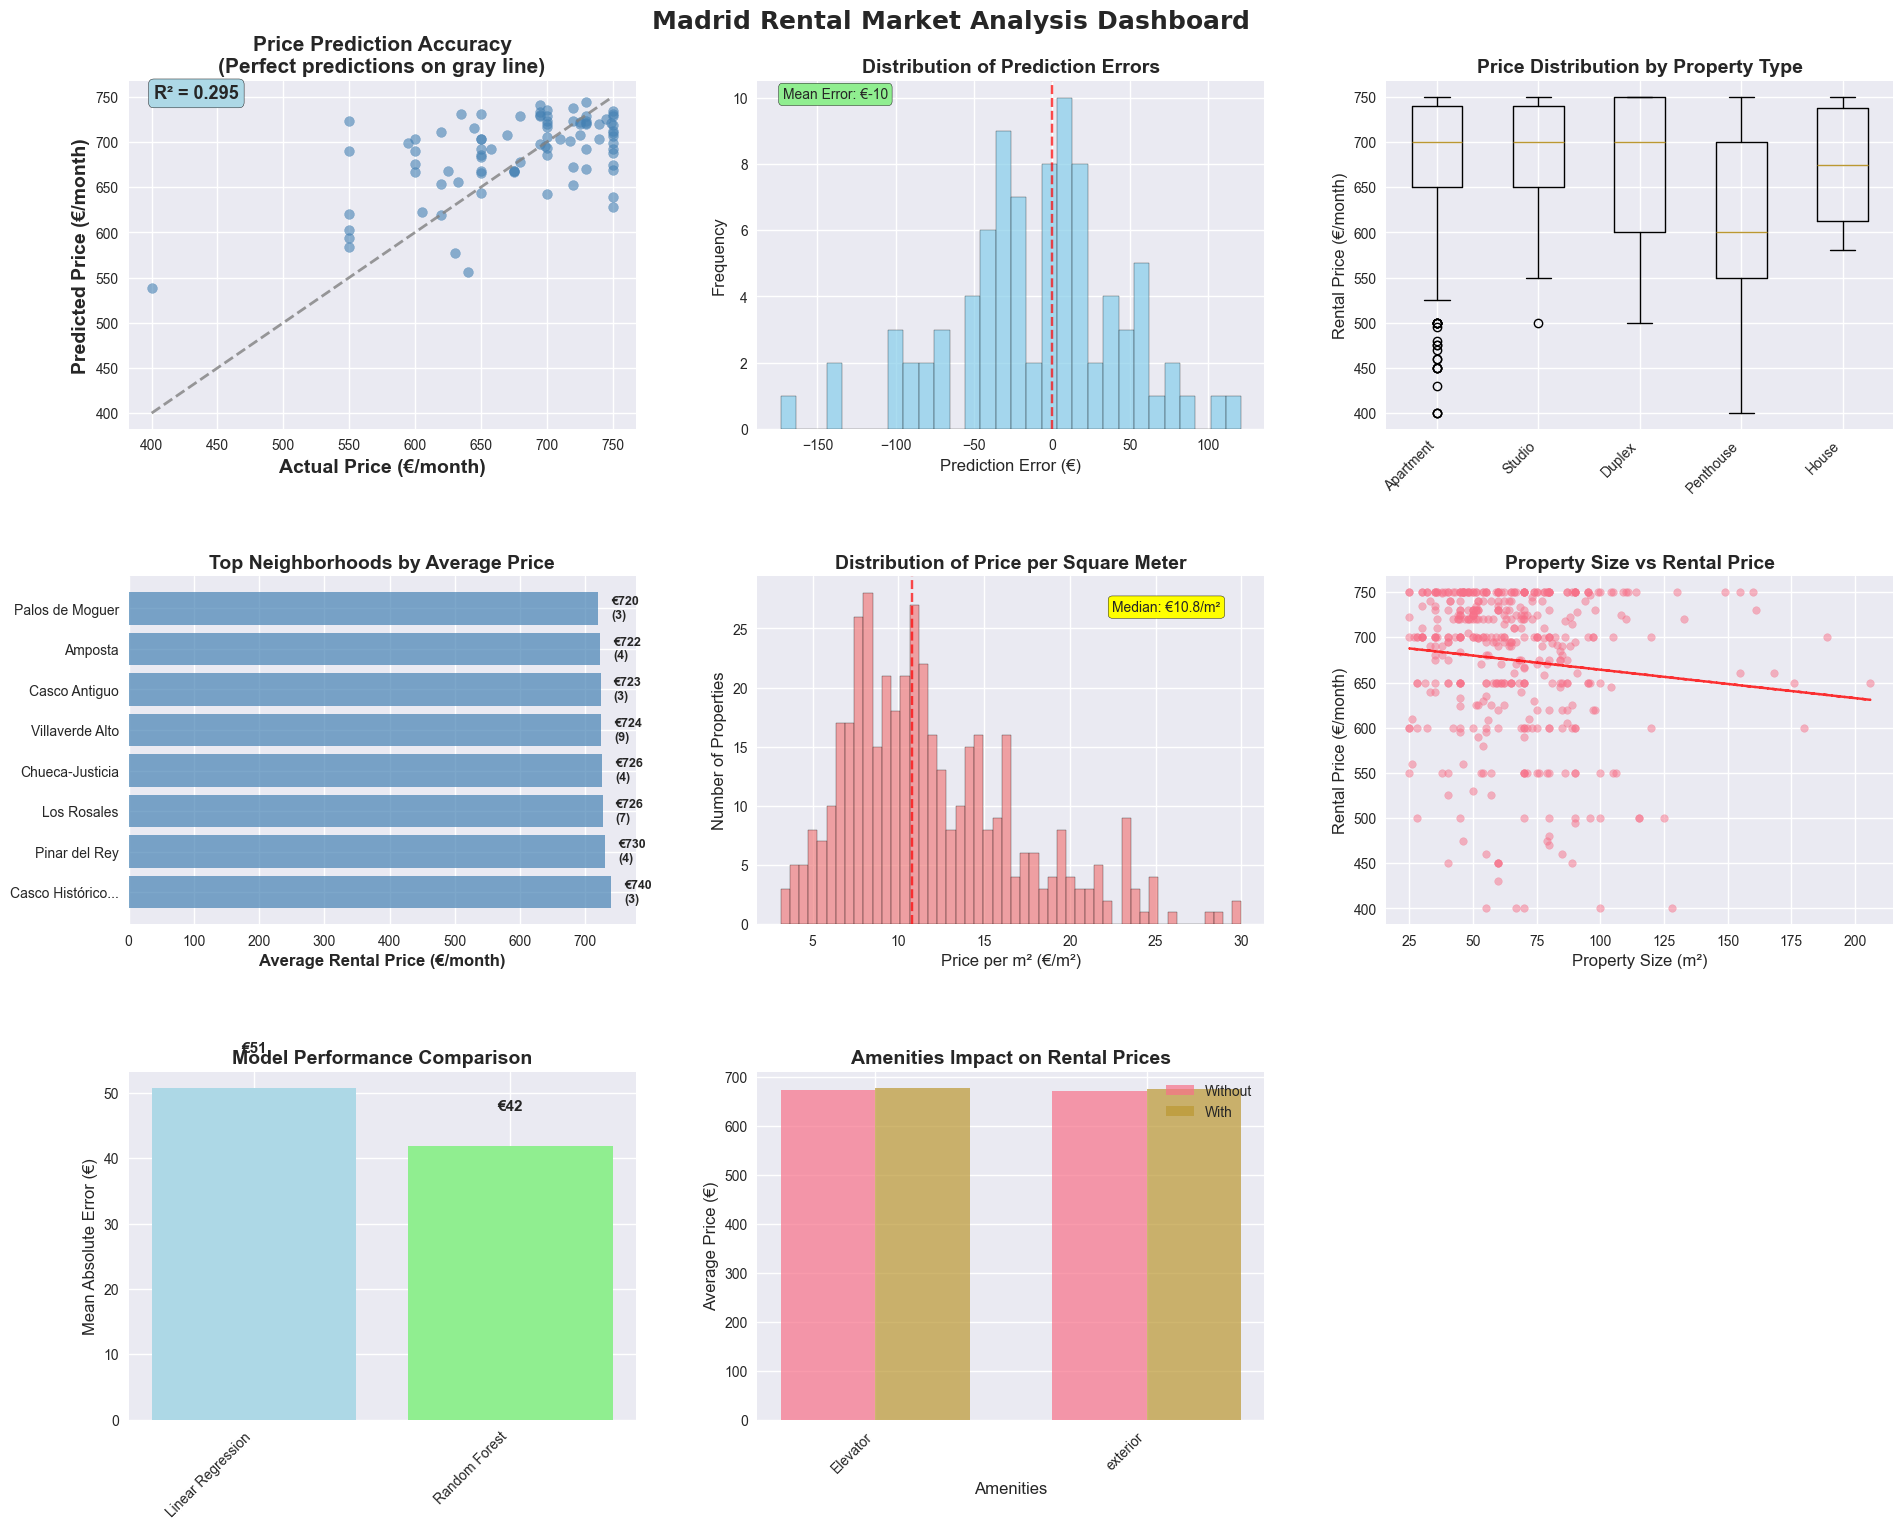

Visualization dashboard created!

KEY FINDINGS:
1. Best model (Random Forest) test MAE: €42
2. 92.0% of test predictions are within €100 of the actual rent
3. Size has a weak negative correlation with price in this sample (-0.106)
4. Amenities with a statistically significant price difference (p < 0.05): 0
5. Rents in the cleaned data range from €400 to €750, so the model does not cover higher-priced rentals


In [46]:
# Model Evaluation and Visualizations
print("CREATING VISUALIZATIONS")


# Set up the plotting environment
fig = plt.figure(figsize=(20, 16))

# 1. Actual vs Predicted Prices Scatter Plot
plt.subplot(3, 3, 1)
plt.scatter(y_test, y_pred_best, alpha=0.6, s=50, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='gray', lw=2, alpha=0.8)
plt.xlabel('Actual Price (€/month)', fontsize=14, fontweight='bold')
plt.ylabel('Predicted Price (€/month)', fontsize=14, fontweight='bold')
plt.title('Price Prediction Accuracy\n(Perfect predictions on gray line)', fontsize=15, fontweight='bold')

# Add R² score to the plot
r2_best = model_results[best_model_name]['test_r2']
plt.text(0.05, 0.95, f'R² = {r2_best:.3f}', transform=plt.gca().transAxes, 
         bbox=dict(boxstyle='round', facecolor='lightblue'), fontsize=13, fontweight='bold')

# 2. Prediction Error Distribution
plt.subplot(3, 3, 2)
prediction_errors = y_test - y_pred_best
plt.hist(prediction_errors, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('Prediction Error (€)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of Prediction Errors', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='red', linestyle='--', alpha=0.7)

# Add mean error
mean_error = prediction_errors.mean()
plt.text(0.05, 0.95, f'Mean Error: €{mean_error:.0f}', transform=plt.gca().transAxes,
         bbox=dict(boxstyle='round', facecolor='lightgreen'), fontsize=10)

# 3. Price Distribution by Property Type
plt.subplot(3, 3, 3)
if 'property_category' in df.columns:
    property_prices = []
    property_labels = []
    
    for prop_type in df['property_category'].value_counts().head(5).index:
        prices = df[df['property_category'] == prop_type]['price']
        if len(prices) > 0:
            property_prices.append(prices)
            property_labels.append(prop_type)
    
    if property_prices:
        plt.boxplot(property_prices, labels=property_labels)
        plt.xticks(rotation=45, ha='right')
        plt.ylabel('Rental Price (€/month)', fontsize=12)
        plt.title('Price Distribution by Property Type', fontsize=14, fontweight='bold')

# 4. Average Price by Top Neighborhoods
plt.subplot(3, 3, 4)
try:
    # Get neighborhood price data directly from DataFrame
    neighborhood_col = None
    
    # Check which neighborhood column exists
    for col in ['neighborhood', 'barrio', 'district']:
        if col in df.columns and df[col].notna().sum() > 0:
            neighborhood_col = col
            break
    
    if neighborhood_col:
        # Create neighborhood analysis
        neighborhood_data = df.groupby(neighborhood_col).agg({
            'price': ['mean', 'count']
        }).reset_index()
        
        # Flatten column names
        neighborhood_data.columns = ['neighborhood', 'avg_price', 'count']
        
        # Filter neighborhoods with at least 3 properties and remove nulls
        neighborhood_data = neighborhood_data[
            (neighborhood_data['count'] >= 3) & 
            (neighborhood_data['neighborhood'].notna()) &
            (neighborhood_data['neighborhood'] != '') &
            (neighborhood_data['neighborhood'] != 'None')
        ]
        
        # Sort by average price and take top 8
        neighborhood_data = neighborhood_data.sort_values('avg_price', ascending=False).head(8)
        
        if len(neighborhood_data) > 0:
            # Create horizontal bar chart
            y_pos = range(len(neighborhood_data))
            plt.barh(y_pos, neighborhood_data['avg_price'], color='steelblue', alpha=0.7)
            
            # Format neighborhood names (truncate if too long)
            neighborhood_labels = [
                name[:15] + '...' if len(str(name)) > 18 else str(name) 
                for name in neighborhood_data['neighborhood']
            ]
            
            plt.yticks(y_pos, neighborhood_labels, fontsize=10)
            plt.xlabel('Average Rental Price (€/month)', fontsize=12, fontweight='bold')
            plt.title('Top Neighborhoods by Average Price', fontsize=14, fontweight='bold')
            
            # Add value labels
            for i, (v, count) in enumerate(zip(neighborhood_data['avg_price'], neighborhood_data['count'])):
                plt.text(v + 20, i, f'€{v:.0f}\n({count})', va='center', fontsize=9, fontweight='bold')
        else:
            plt.text(0.5, 0.5, 'Insufficient neighborhood\ndata for analysis\n(need 3+ properties per area)', 
                     ha='center', va='center', transform=plt.gca().transAxes, fontsize=12)
    else:
        plt.text(0.5, 0.5, f'Neighborhood columns not found\nAvailable: {list(df.columns[:10])}...', 
                 ha='center', va='center', transform=plt.gca().transAxes, fontsize=10)
        
except Exception as e:
    plt.text(0.5, 0.5, f'Neighborhood analysis\nerror: {str(e)[:40]}...', 
             ha='center', va='center', transform=plt.gca().transAxes, fontsize=11)
    print(f"Debug - Neighborhood error: {e}")
    print(f"Debug - Available columns: {list(df.columns)}")

# 5. Price per Square Meter Analysis
plt.subplot(3, 3, 5)
if 'price_per_sqm' in df.columns:
    plt.hist(df['price_per_sqm'], bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
    plt.xlabel('Price per m² (€/m²)', fontsize=12)
    plt.ylabel('Number of Properties', fontsize=12)
    plt.title('Distribution of Price per Square Meter', fontsize=14, fontweight='bold')
    
    # Add median line
    median_price_sqm = df['price_per_sqm'].median()
    plt.axvline(x=median_price_sqm, color='red', linestyle='--', alpha=0.7)
    plt.text(0.7, 0.9, f'Median: €{median_price_sqm:.1f}/m²', transform=plt.gca().transAxes,
             bbox=dict(boxstyle='round', facecolor='yellow'), fontsize=10)

# 6. Property Size vs Price Relationship
plt.subplot(3, 3, 6)
if 'size' in df.columns:
    plt.scatter(df['size'], df['price'], alpha=0.5, s=30)
    plt.xlabel('Property Size (m²)', fontsize=12)
    plt.ylabel('Rental Price (€/month)', fontsize=12)
    plt.title('Property Size vs Rental Price', fontsize=14, fontweight='bold')
    
    # Add trend line
    z = np.polyfit(df['size'].dropna(), df[df['size'].notna()]['price'], 1)
    p = np.poly1d(z)
    plt.plot(df['size'], p(df['size']), "r--", alpha=0.8)

# 7. Model Performance Comparison
plt.subplot(3, 3, 7)
model_names = list(model_results.keys())
mae_scores = [model_results[name]['test_mae'] for name in model_names]

bars = plt.bar(model_names, mae_scores, color=['lightblue', 'lightgreen'])
plt.ylabel('Mean Absolute Error (€)', fontsize=12)
plt.title('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')

# Add value labels on bars
for bar, mae in zip(bars, mae_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
             f'€{mae:.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# 8. Amenities Impact Analysis
plt.subplot(3, 3, 8)
try:
    # Amenities comparison
    amenities_data = []
    amenity_labels = []
    
    for amenity_col in ['hasLift_binary', 'exterior_binary', 'parkingSpace_binary']:
        if amenity_col in df.columns:
            with_amenity = df[df[amenity_col] == 1]['price'].mean()
            without_amenity = df[df[amenity_col] == 0]['price'].mean()
            
            if not pd.isna(with_amenity) and not pd.isna(without_amenity):
                amenities_data.append([without_amenity, with_amenity])
                amenity_name = amenity_col.replace('_binary', '').replace('has', '').replace('Lift', 'Elevator')
                amenity_labels.append(amenity_name)
    
    if amenities_data:
        x_pos = np.arange(len(amenity_labels))
        without = [data[0] for data in amenities_data]
        with_amenity = [data[1] for data in amenities_data]
        
        width = 0.35
        plt.bar(x_pos - width/2, without, width, label='Without', alpha=0.7)
        plt.bar(x_pos + width/2, with_amenity, width, label='With', alpha=0.7)
        
        plt.xlabel('Amenities', fontsize=12)
        plt.ylabel('Average Price (€)', fontsize=12)
        plt.title('Amenities Impact on Rental Prices', fontsize=14, fontweight='bold')
        plt.xticks(x_pos, amenity_labels, rotation=45, ha='right')
        plt.legend()
        
except Exception as e:
    plt.text(0.5, 0.5, 'Amenities data\nanalysis unavailable', ha='center', va='center',
             transform=plt.gca().transAxes, fontsize=12)

plt.tight_layout(pad=3.0)
plt.suptitle('Madrid Rental Market Analysis Dashboard', fontsize=18, fontweight='bold', y=0.98)

plt.show()

print("Visualization dashboard created!")

# Key findings
print(f"\nKEY FINDINGS:")
print("="*50)
print(f"1. Best model ({best_model_name}) test MAE: €{best_mae:.0f}")
print(f"2. {accuracy_ranges['within_100']:.1f}% of test predictions are within €100 of the actual rent")
print(f"3. Size has a weak negative correlation with price in this sample ({size_price_corr:.3f})")
print(f"4. Amenities with a statistically significant price difference (p < 0.05): {len(significant_amenities)}")
print(f"5. Rents in the cleaned data range from €{df['price'].min():.0f} to €{df['price'].max():.0f}, so the model does not cover higher-priced rentals")

## 9. Summary and Limitations

A short summary of the market data, the price model and data quality.

**Limitations**

- Rents in the source data only go up to €750 per month, so the results describe the lower end of the Madrid rental market and the model should not be used for more expensive listings.
- The data is not limited to the city of Madrid; it also contains listings from nearby towns and provinces (for example Toledo).
- After cleaning, neighborhood is missing for 253 of 431 listings and district for 89, which limits the location features.
- Both models overfit (training MAE well below test MAE), and a test R² of 0.295 means most of the variation in rent is not explained by the available features.
- Neither elevator nor exterior showed a statistically significant effect on rent, and no listing had a parking space after cleaning.

In [48]:
# Summary of the analysis
print("SUMMARY")
print("="*60)

# Close database connection
if 'conn' in locals():
    conn.close()
    print("Database connection closed")

# 1. Market overview
print(f"\n1. MARKET OVERVIEW")
print("-" * 50)

total_properties = len(df)
avg_price = df['price'].mean()
avg_size = df['size'].mean() if 'size' in df.columns else 0
price_std = df['price'].std()

print(f"   - Total Properties Analyzed: {total_properties:,}")
print(f"   - Average Monthly Rent: €{avg_price:.0f}")
print(f"   - Price Standard Deviation: €{price_std:.0f}")
print(f"   - Average Property Size: {avg_size:.0f}m²")

# 2. Price model
print(f"\n2. PRICE MODEL")
print("-" * 50)
print(f"   - Best Model: {best_model_name}")
print(f"   - Test MAE: €{best_mae:.0f}")
print(f"   - Predictions within €100: {accuracy_ranges['within_100']:.1f}%")

# 3. Data quality
print(f"\n3. DATA QUALITY")
print("-" * 50)

data_quality_metrics = {
    'Missing Data Rate': f"{(df.isnull().sum().sum() / (len(df) * len(df.columns))) * 100:.1f}%",
    'Rows Removed During Cleaning': f"{((original_size - final_size) / original_size) * 100:.1f}%",
    'Model Features': f"{len(feature_columns)}"
}

for metric, value in data_quality_metrics.items():
    print(f"   - {metric}: {value}")

SUMMARY
Database connection closed

1. MARKET OVERVIEW
--------------------------------------------------
   - Total Properties Analyzed: 431
   - Average Monthly Rent: €675
   - Price Standard Deviation: €80
   - Average Property Size: 66m²

2. PRICE MODEL
--------------------------------------------------
   - Best Model: Random Forest
   - Test MAE: €42
   - Predictions within €100: 92.0%

3. DATA QUALITY
--------------------------------------------------
   - Missing Data Rate: 8.3%
   - Rows Removed During Cleaning: 4.2%
   - Model Features: 11
